# Email Spam Detector

- Classer un email : **spam** ou **ham** (email normal)
- Machine learning classique (scikit-learn)
- Méthode du livre *Hands-On Machine Learning*

## 1. Le problème

- Classification binaire : spam = 1, ham = 0
- Faux positif (vrai email → spam) = **grave**
- Métrique principale : **la précision**

**Import des bibliothèques et réglages des graphiques.**

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("Python", sys.version.split()[0], "| scikit-learn", sklearn.__version__)

np.random.seed(42)
plt.rc("font", size=11)
plt.rc("axes", titlesize=12, labelsize=11)

IMAGES_PATH = Path("images")
IMAGES_PATH.mkdir(exist_ok=True)


def save_fig(fig_id, tight_layout=True, resolution=150):
    # Comme dans le livre : on sauvegarde chaque figure dans images/
    if tight_layout:
        plt.tight_layout()
    plt.savefig(IMAGES_PATH / f"{fig_id}.png", dpi=resolution)

Python 3.12.13 | scikit-learn 1.9.1


## 2. Les données

**Téléchargement et chargement du jeu UCI Spambase.**

In [2]:
import urllib.request
import zipfile

DATA_URL = "https://archive.ics.uci.edu/static/public/94/spambase.zip"
DATA_PATH = Path("data")


def load_spambase_data():
    data_file = DATA_PATH / "spambase.data"
    if not data_file.is_file():
        DATA_PATH.mkdir(parents=True, exist_ok=True)
        zip_path = DATA_PATH / "spambase.zip"
        urllib.request.urlretrieve(DATA_URL, zip_path)
        with zipfile.ZipFile(zip_path) as z:
            z.extractall(DATA_PATH)

    # Les noms des colonnes sont dans spambase.names (lignes "nom: continuous.")
    names = []
    for line in (DATA_PATH / "spambase.names").read_text().splitlines():
        if line and not line.startswith("|") and line.endswith("continuous."):
            names.append(line.split(":")[0].strip())
    names.append("spam")
    return pd.read_csv(data_file, header=None, names=names)


emails = load_spambase_data()
emails.shape

(4601, 58)

## 3. Premier coup d'œil

**Les 5 premières lignes du tableau.**

In [3]:
emails.head()

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,spam
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


**Type de chaque colonne et valeurs manquantes.**

In [4]:
emails.info()

<class 'pandas.DataFrame'>
RangeIndex: 4601 entries, 0 to 4600
Data columns (total 58 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   word_freq_make              4601 non-null   float64
 1   word_freq_address           4601 non-null   float64
 2   word_freq_all               4601 non-null   float64
 3   word_freq_3d                4601 non-null   float64
 4   word_freq_our               4601 non-null   float64
 5   word_freq_over              4601 non-null   float64
 6   word_freq_remove            4601 non-null   float64
 7   word_freq_internet          4601 non-null   float64
 8   word_freq_order             4601 non-null   float64
 9   word_freq_mail              4601 non-null   float64
 10  word_freq_receive           4601 non-null   float64
 11  word_freq_will              4601 non-null   float64
 12  word_freq_people            4601 non-null   float64
 13  word_freq_report            4601 non-null   

**Statistiques de base : moyenne, min, max…**

In [5]:
emails.describe().T.head(15)

,count,mean,std,min,25%,50%,75%,max
word_freq_make,4601.0,0.104553,0.305358,0.0,0.0,0.0,0.00,4.54
word_freq_address,4601.0,0.213015,1.290575,0.0,0.0,0.0,0.00,14.28
word_freq_all,4601.0,0.280656,0.504143,0.0,0.0,0.0,0.42,5.10
word_freq_3d,4601.0,0.065425,1.395151,0.0,0.0,0.0,0.00,42.81
word_freq_our,4601.0,0.312223,0.672513,0.0,0.0,0.0,0.38,10.00
word_freq_over,4601.0,0.095901,0.273824,0.0,0.0,0.0,0.00,5.88
word_freq_remove,4601.0,0.114208,0.391441,0.0,0.0,0.0,0.00,7.27
word_freq_internet,4601.0,0.105295,0.401071,0.0,0.0,0.0,0.00,11.11
word_freq_order,4601.0,0.090067,0.278616,0.0,0.0,0.0,0.00,5.26
word_freq_mail,4601.0,0.239413,0.644755,0.0,0.0,0.0,0.16,18.18


**Valeurs manquantes, doublons et proportion de spam.**

In [6]:
print("Valeurs manquantes :", emails.isna().sum().sum())
print("Lignes en double   :", emails.duplicated().sum())
print()
print(emails["spam"].value_counts().rename({0: "ham", 1: "spam"}))
print()
print(emails["spam"].value_counts(normalize=True).rename({0: "ham", 1: "spam"}).round(3))

Valeurs manquantes : 0
Lignes en double   : 391

spam
ham     2788
spam    1813
Name: count, dtype: int64

spam
ham     0.606
spam    0.394
Name: proportion, dtype: float64


**Courbes : histogramme de chaque variable.**

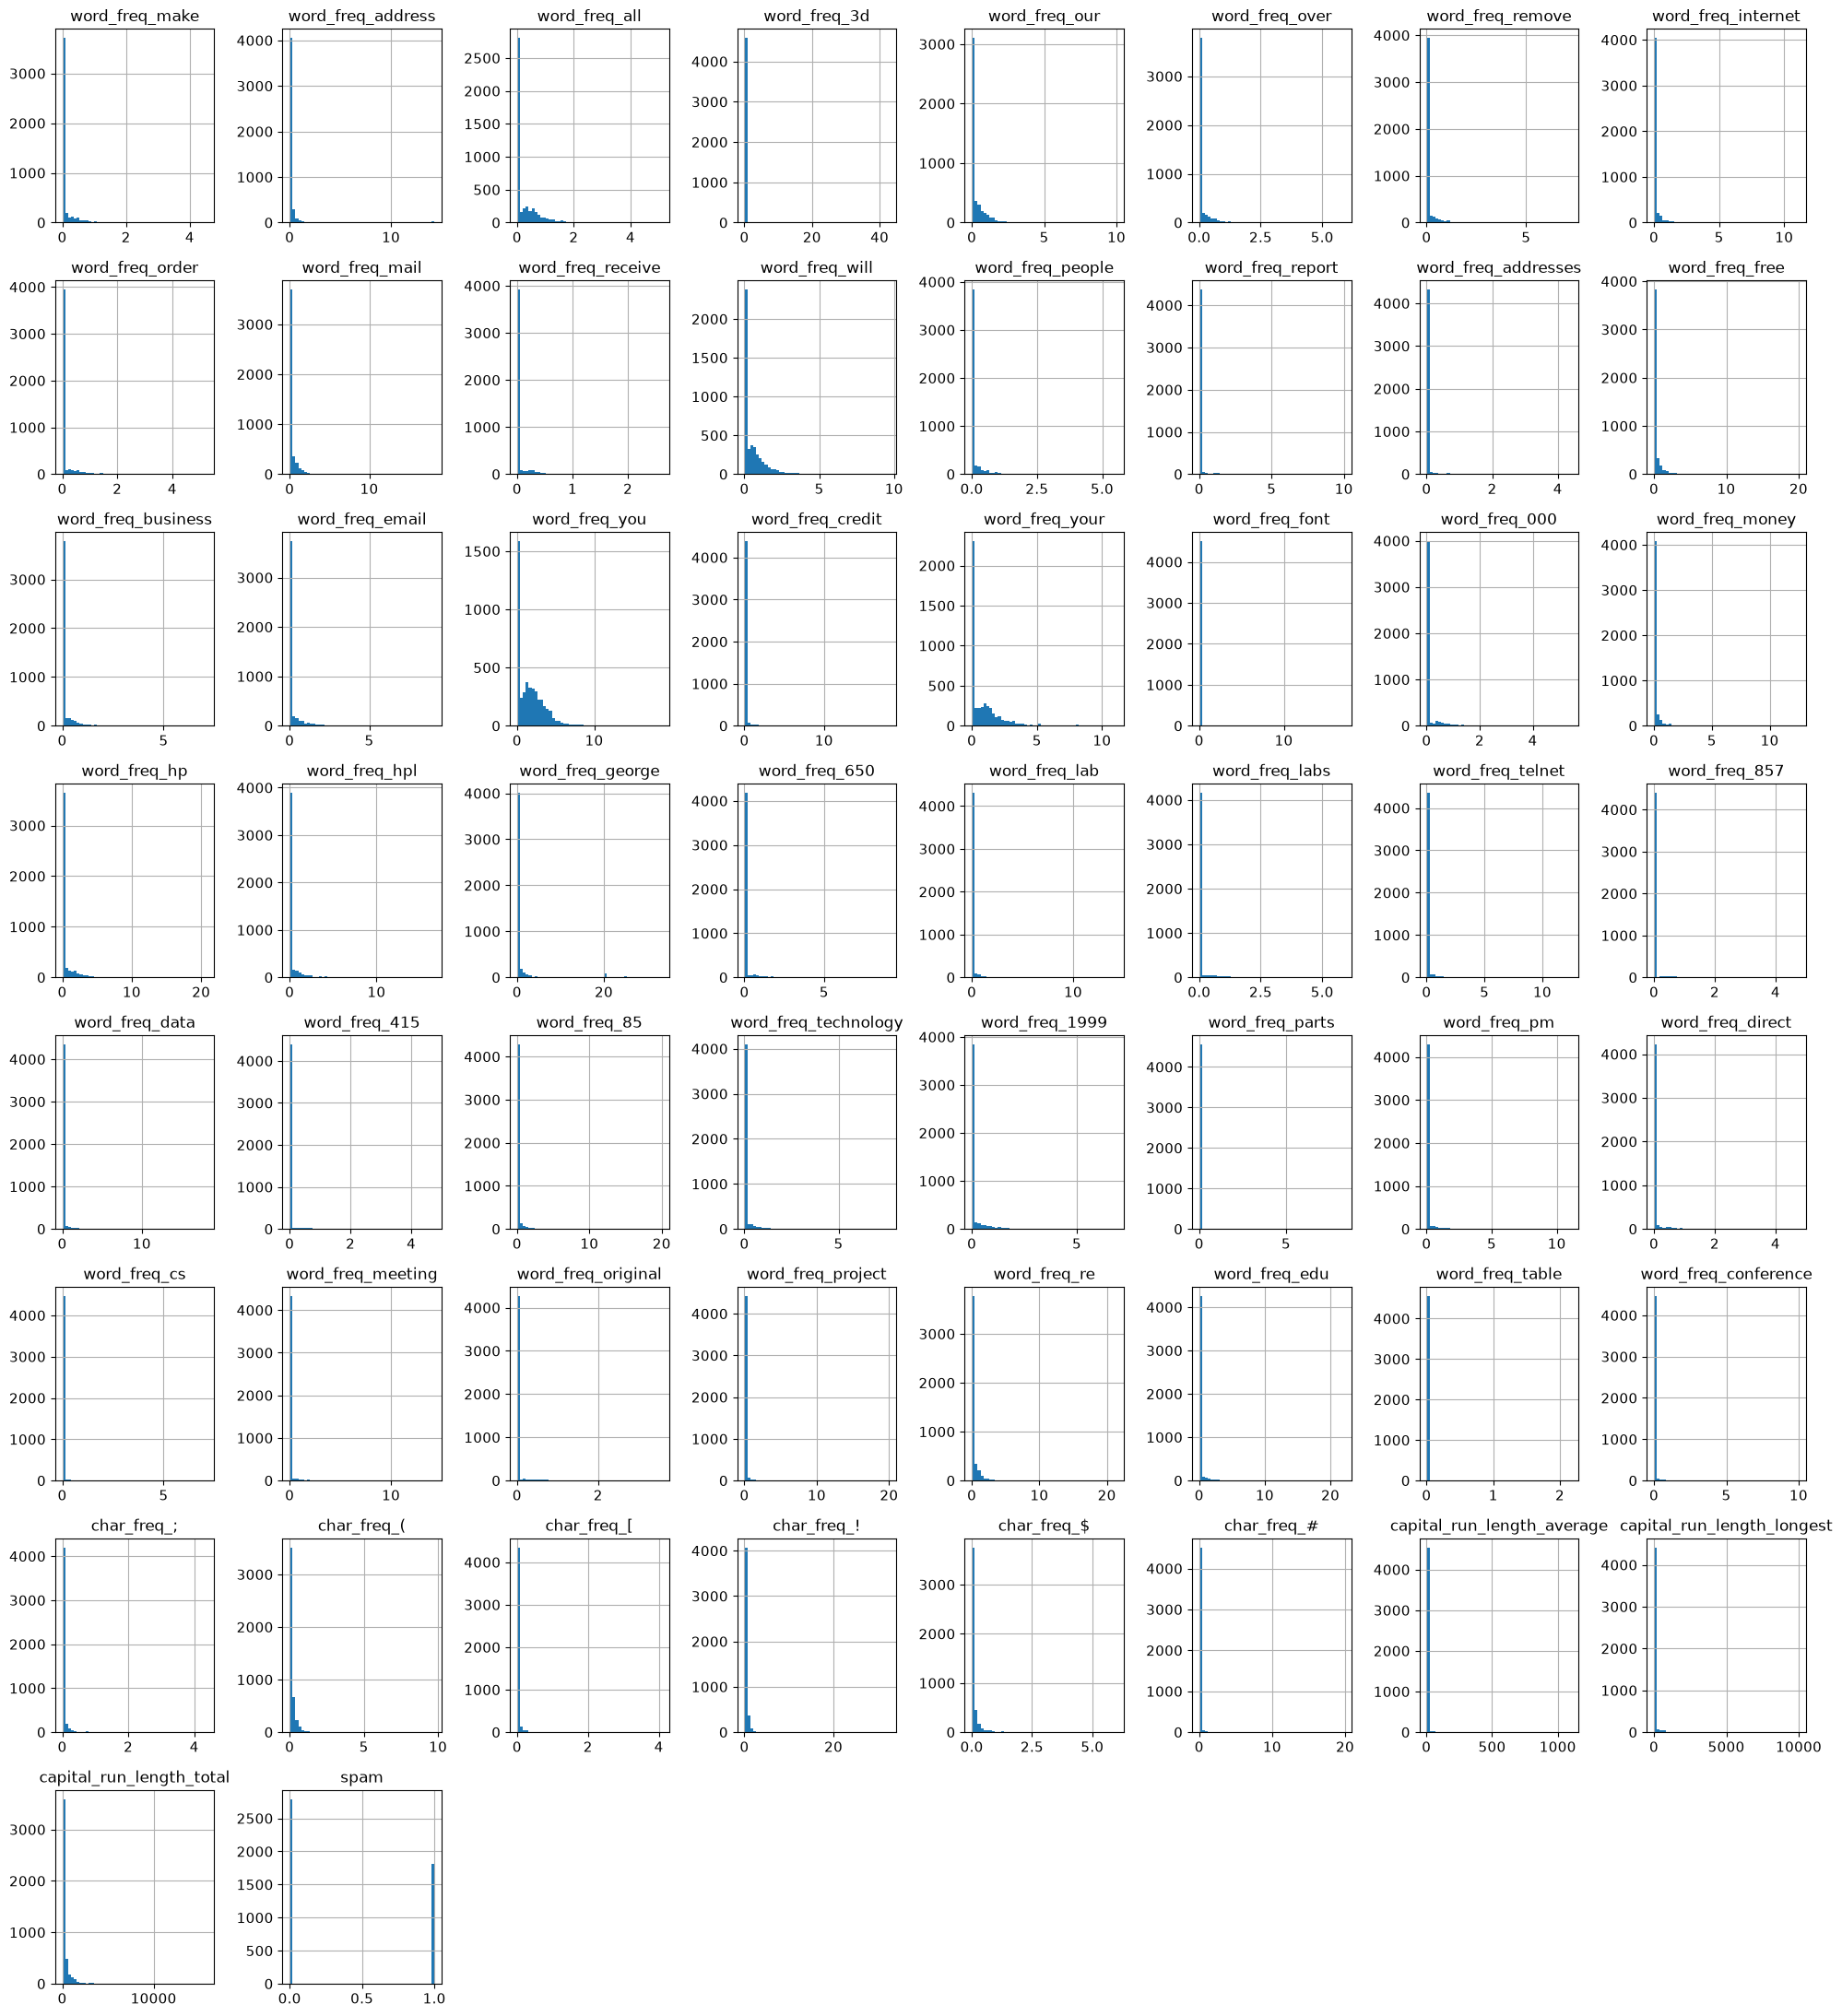

In [7]:
emails.hist(bins=50, figsize=(20, 22))
save_fig("histogrammes_variables")
plt.show()

- Aucune valeur manquante
- ~40 % de spam
- Échelles très différentes, beaucoup de 0 → à transformer
- 391 doublons → à supprimer

## 4. Le jeu de test

**Suppression des doublons, puis découpage 80 % train / 20 % test (stratifié).**

In [8]:
from sklearn.model_selection import train_test_split

emails = emails.drop_duplicates().reset_index(drop=True)
print("Emails après suppression des doublons :", len(emails))

train_set, test_set = train_test_split(
    emails, test_size=0.2, stratify=emails["spam"], random_state=42
)
print("Train :", len(train_set), "| Test :", len(test_set))

Emails après suppression des doublons : 4210
Train : 3368 | Test : 842


**Vérification : même proportion de spam partout.**

In [9]:
# Vérification : la stratification conserve bien la proportion de spam
pd.DataFrame({
    "Complet": emails["spam"].value_counts(normalize=True),
    "Train": train_set["spam"].value_counts(normalize=True),
    "Test": test_set["spam"].value_counts(normalize=True),
}).rename(index={0: "ham", 1: "spam"}).round(4)

,Complet,Train,Test
spam,,,
ham,0.6012,0.6012,0.601
spam,0.3988,0.3988,0.399


## 5. Exploration (train seulement)

**Les variables les plus liées au spam et au ham.**

In [10]:
spam_explore = train_set.copy()

corr = spam_explore.corr()["spam"].drop("spam").sort_values(ascending=False)
print("Variables les plus corrélées au spam :")
print(corr.head(10).round(3))
print()
print("Variables les plus corrélées au ham :")
print(corr.tail(10).round(3))

Variables les plus corrélées au spam :
word_freq_your              0.385
word_freq_remove            0.339
word_freq_000               0.321
char_freq_$                 0.319
word_freq_free              0.295
word_freq_receive           0.269
word_freq_business          0.262
word_freq_you               0.256
char_freq_!                 0.237
capital_run_length_total    0.231
Name: spam, dtype: float64

Variables les plus corrélées au ham :
word_freq_85         -0.151
word_freq_original   -0.151
word_freq_re         -0.152
word_freq_edu        -0.153
word_freq_650        -0.160
word_freq_george     -0.168
word_freq_labs       -0.185
word_freq_1999       -0.211
word_freq_hpl        -0.242
word_freq_hp         -0.272
Name: spam, dtype: float64


**Courbe : corrélation de chaque variable avec le spam (rouge = spam, bleu = ham).**

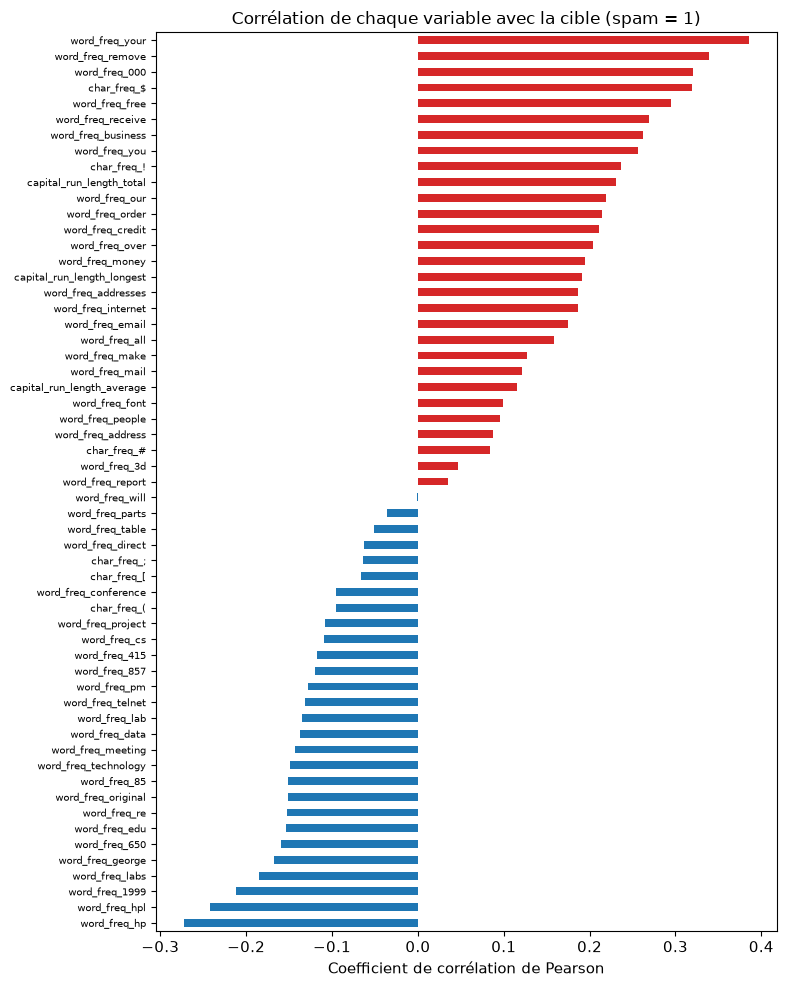

In [11]:
fig, ax = plt.subplots(figsize=(8, 10))
corr.sort_values().plot.barh(ax=ax, color=np.where(corr.sort_values() > 0, "tab:red", "tab:blue"))
ax.set_title("Corrélation de chaque variable avec la cible (spam = 1)")
ax.set_xlabel("Coefficient de corrélation de Pearson")
ax.tick_params(axis="y", labelsize=7)
save_fig("correlation_cible")
plt.show()

**Moyenne de quelques variables : ham contre spam.**

In [12]:
# Moyenne de quelques variables clés selon la classe
top = list(corr.head(6).index) + list(corr.tail(4).index)
spam_explore.groupby("spam")[top].mean().T.rename(columns={0: "ham", 1: "spam"}).round(3)

spam,ham,spam
word_freq_your,0.445,1.340
word_freq_remove,0.008,0.274
word_freq_000,0.008,0.241
char_freq_$,0.012,0.175
word_freq_free,0.068,0.543
word_freq_receive,0.016,0.115
word_freq_labs,0.165,0.006
word_freq_1999,0.219,0.033
word_freq_hpl,0.460,0.010
word_freq_hp,0.926,0.019


**Courbes : distribution des variables clés, spam (rouge) contre ham (bleu).**

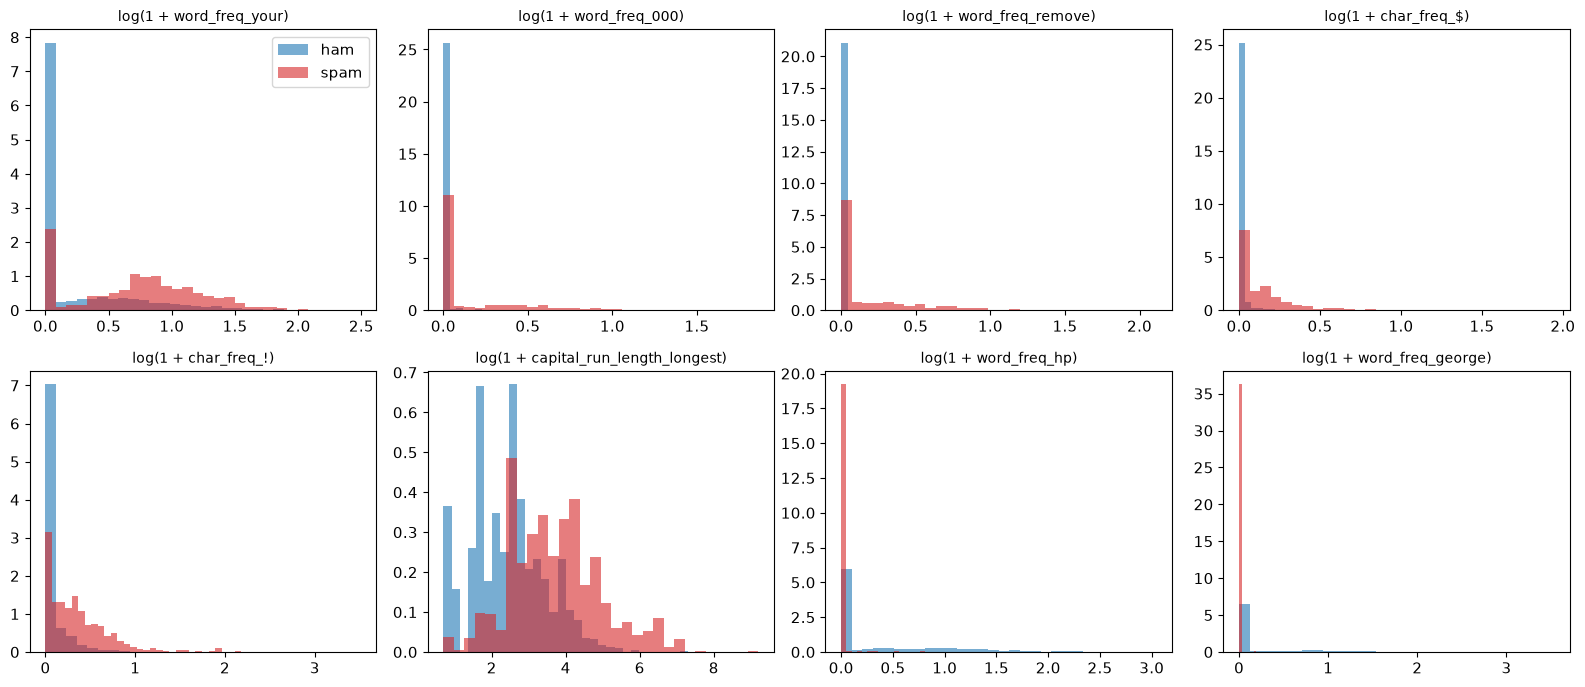

In [13]:
# Distributions (en échelle log, à cause de la longue traîne) pour les variables les plus discriminantes
features = ["word_freq_your", "word_freq_000", "word_freq_remove", "char_freq_$",
            "char_freq_!", "capital_run_length_longest", "word_freq_hp", "word_freq_george"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, feat in zip(axes.ravel(), features):
    for label, color, name in [(0, "tab:blue", "ham"), (1, "tab:red", "spam")]:
        values = np.log1p(spam_explore.loc[spam_explore["spam"] == label, feat])
        ax.hist(values, bins=30, alpha=0.6, color=color, label=name, density=True)
    ax.set_title(f"log(1 + {feat})", fontsize=10)
axes[0, 0].legend()
save_fig("distributions_spam_vs_ham")
plt.show()

**Courbe : corrélations entre les 15 variables les plus importantes.**

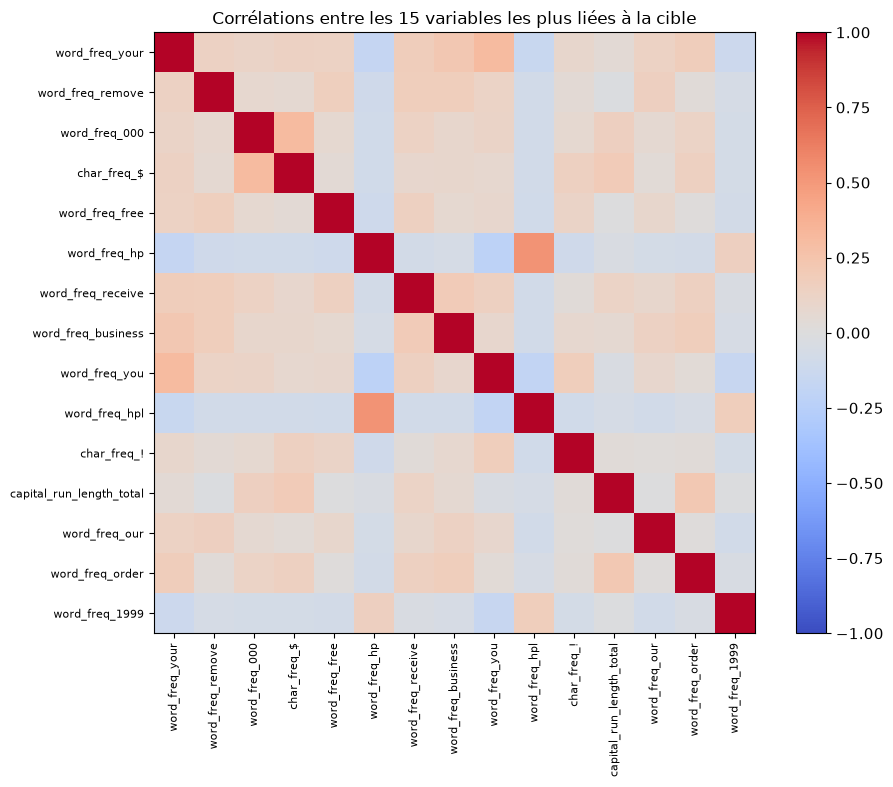

In [14]:
# Matrice de corrélation entre variables (les plus liées à la cible)
cols = list(corr.abs().sort_values(ascending=False).head(15).index)
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(spam_explore[cols].corr(), cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=90, fontsize=8)
ax.set_yticks(range(len(cols)), cols, fontsize=8)
fig.colorbar(im, ax=ax)
ax.set_title("Corrélations entre les 15 variables les plus liées à la cible")
save_fig("matrice_correlation")
plt.show()

- Spam : `your`, `000`, `remove`, `free`, `$`, `!`
- Ham : `hp`, `george`, `1999` (mots propres à HP)
- Aucune variable seule ne suffit

## 6. Préparation des données

**Séparer les variables (X) et la réponse (y).**

In [15]:
X_train = train_set.drop("spam", axis=1)
y_train = train_set["spam"].copy()
X_test = test_set.drop("spam", axis=1)
y_test = test_set["spam"].copy()

X_train.shape, X_test.shape

((3368, 57), (842, 57))

**Pipeline : log(1 + x) puis mise à l'échelle.**

In [16]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

log_transformer = FunctionTransformer(np.log1p, feature_names_out="one-to-one")
preprocessing = make_pipeline(log_transformer, StandardScaler())

X_train_prepared = preprocessing.fit_transform(X_train)
print(X_train_prepared.shape)
pd.DataFrame(X_train_prepared, columns=X_train.columns).describe().T[["mean", "std"]].head().round(3)

(3368, 57)


,mean,std
word_freq_make,0.0,1.0
word_freq_address,-0.0,1.0
word_freq_all,0.0,1.0
word_freq_3d,-0.0,1.0
word_freq_our,0.0,1.0


## 7. Comparaison des modèles

**Entraîner 6 modèles et les noter par validation croisée (10 plis).**

In [17]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.svm import SVC
import warnings
from sklearn.exceptions import UndefinedMetricWarning

# La baseline ne prédit jamais "spam" : sa précision est indéfinie (on la note 0), on masque l'avertissement
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)

models = {
    "Dummy (baseline)": make_pipeline(preprocessing, DummyClassifier(strategy="most_frequent")),
    "Gaussian Naive Bayes": make_pipeline(preprocessing, GaussianNB()),
    "Multinomial Naive Bayes": MultinomialNB(),  # sur les fréquences brutes (doivent être >= 0)
    "Logistic Regression": make_pipeline(preprocessing, LogisticRegression(max_iter=1000, random_state=42)),
    "SVM (RBF)": make_pipeline(preprocessing, SVC(random_state=42)),
    "Random Forest": make_pipeline(preprocessing, RandomForestClassifier(random_state=42, n_jobs=-1)),
}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
scoring = ["accuracy", "precision", "recall", "f1", "average_precision"]

results = {}
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    results[name] = {m: scores[f"test_{m}"].mean() for m in scoring}
    results[name]["f1_std"] = scores["test_f1"].std()

results_df = pd.DataFrame(results).T.sort_values("f1", ascending=False)
results_df.round(4)

,accuracy,precision,recall,f1,average_precision,f1_std
Random Forest,0.9481,0.9459,0.9226,0.9340,0.9777,0.0187
SVM (RBF),0.9388,0.9360,0.9092,0.9222,0.9675,0.0223
Logistic Regression,0.9353,0.9288,0.9077,0.9180,0.9689,0.0199
Gaussian Naive Bayes,0.8358,0.7243,0.9531,0.8228,0.9038,0.0223
Multinomial Naive Bayes,0.8017,0.7695,0.7186,0.7428,0.7883,0.0276
Dummy (baseline),0.6012,0.0000,0.0000,0.0000,0.3988,0.0000


**Courbe : scores des modèles côte à côte.**

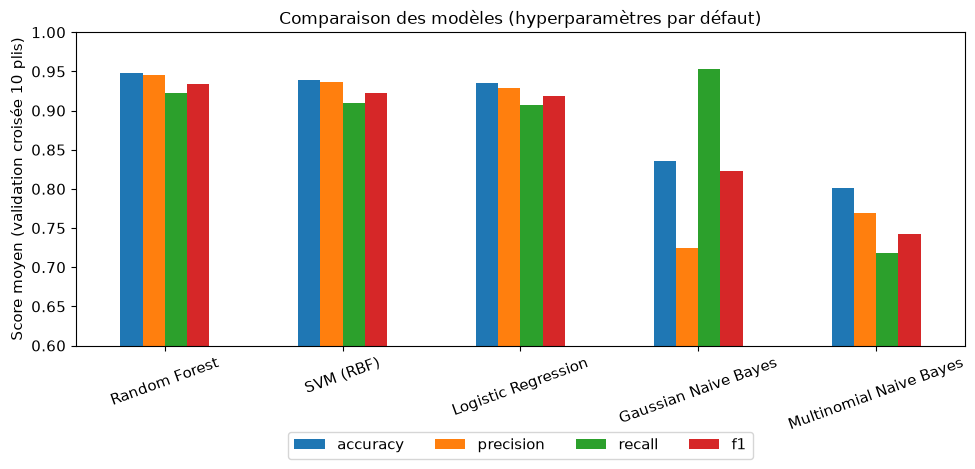

In [18]:
fig, ax = plt.subplots(figsize=(10, 5))
results_df.drop(index="Dummy (baseline)")[["accuracy", "precision", "recall", "f1"]].plot.bar(ax=ax)
ax.set_ylim(0.6, 1.0)
ax.set_ylabel("Score moyen (validation croisée 10 plis)")
ax.set_title("Comparaison des modèles (hyperparamètres par défaut)")
ax.legend(loc="upper center", ncol=4, bbox_to_anchor=(0.5, -0.25))
plt.xticks(rotation=20)
save_fig("comparaison_modeles")
plt.show()

- Meilleur : **Random Forest**
- SVM ≈ régression logistique
- Naive Bayes : le plus faible

## 8. Fine-tuning

**Recherche des meilleurs paramètres de la Random Forest.**

In [19]:
from sklearn.model_selection import GridSearchCV

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rf_pipeline = make_pipeline(preprocessing, RandomForestClassifier(random_state=42, n_jobs=-1))
rf_param_grid = {
    "randomforestclassifier__n_estimators": [200, 500],
    "randomforestclassifier__max_features": ["sqrt", 0.2, 0.4],
    "randomforestclassifier__min_samples_leaf": [1, 2],
}
rf_search = GridSearchCV(rf_pipeline, rf_param_grid, cv=cv5, scoring="average_precision", n_jobs=-1)
rf_search.fit(X_train, y_train)

print("Random Forest - meilleurs paramètres :", rf_search.best_params_)
print("Random Forest - average precision CV  :", round(rf_search.best_score_, 4))

Random Forest - meilleurs paramètres : {'randomforestclassifier__max_features': 'sqrt', 'randomforestclassifier__min_samples_leaf': 2, 'randomforestclassifier__n_estimators': 500}
Random Forest - average precision CV  : 0.977


**Recherche des meilleurs paramètres du SVM.**

In [20]:
svm_pipeline = make_pipeline(preprocessing, SVC(random_state=42))
svm_param_grid = {
    "svc__C": [0.3, 1, 3, 10, 30],
    "svc__gamma": ["scale", 0.003, 0.01, 0.03],
}
svm_search = GridSearchCV(svm_pipeline, svm_param_grid, cv=cv5, scoring="average_precision", n_jobs=-1)
svm_search.fit(X_train, y_train)

print("SVM - meilleurs paramètres :", svm_search.best_params_)
print("SVM - average precision CV  :", round(svm_search.best_score_, 4))

SVM - meilleurs paramètres : {'svc__C': 10, 'svc__gamma': 0.01}
SVM - average precision CV  : 0.9716


**Les 5 meilleures combinaisons testées.**

In [21]:
# Les 5 meilleures combinaisons testées pour la Random Forest
cv_res = pd.DataFrame(rf_search.cv_results_).sort_values("mean_test_score", ascending=False)
cv_res[["params", "mean_test_score", "std_test_score"]].head()

,params,mean_test_score,std_test_score
3,{'randomforestclassifier__max_features': 'sqrt...,0.977019,0.007289
1,{'randomforestclassifier__max_features': 'sqrt...,0.976986,0.006731
5,"{'randomforestclassifier__max_features': 0.2, ...",0.976047,0.006853
4,"{'randomforestclassifier__max_features': 0.2, ...",0.975618,0.007707
0,{'randomforestclassifier__max_features': 'sqrt...,0.975489,0.007592


**On garde le meilleur des deux modèles.**

In [22]:
searches = {"Random Forest": rf_search, "SVM (RBF)": svm_search}
best_name = max(searches, key=lambda name: searches[name].best_score_)
final_model = searches[best_name].best_estimator_
print("Modèle retenu :", best_name)

Modèle retenu : Random Forest


**Courbe : les 20 variables les plus utilisées par la forêt.**

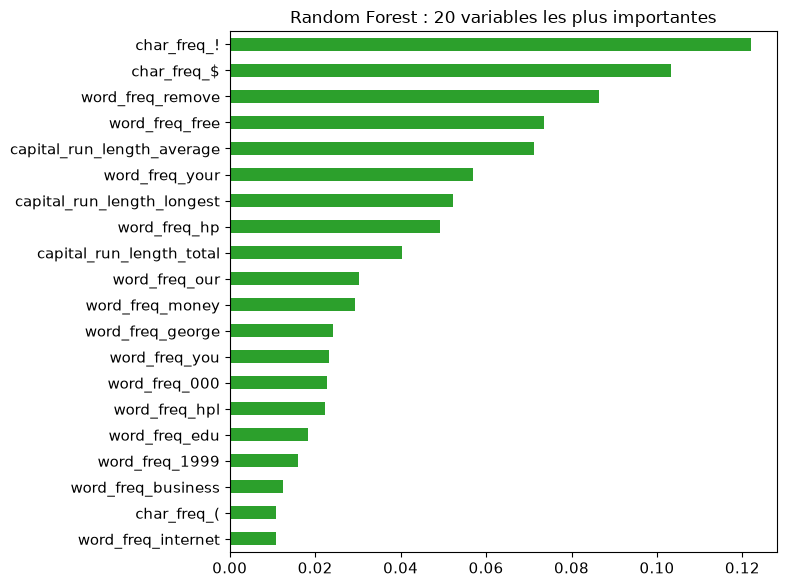

In [23]:
rf_best = rf_search.best_estimator_
importances = pd.Series(
    rf_best[-1].feature_importances_, index=X_train.columns
).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
importances.head(20).sort_values().plot.barh(ax=ax, color="tab:green")
ax.set_title("Random Forest : 20 variables les plus importantes")
save_fig("importance_variables")
plt.show()

## 9. Le seuil de décision

**Rappel obtenu pour chaque précision visée.**

In [24]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve, roc_curve, roc_auc_score

method = "predict_proba" if hasattr(final_model, "predict_proba") else "decision_function"
y_scores = cross_val_predict(final_model, X_train, y_train, cv=cv5, method=method)
if method == "predict_proba":
    y_scores = y_scores[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_train, y_scores)

# Rappel obtenu pour différentes précisions visées
rows = []
for target in [0.95, 0.96, 0.97, 0.98, 0.99]:
    i = np.argmax(precisions[:-1] >= target)  # plus petit seuil qui atteint cette précision
    rows.append({"précision visée": target, "seuil": thresholds[i],
                 "précision (CV)": precisions[i], "rappel (CV)": recalls[i]})
pd.DataFrame(rows).round(3)

,précision visée,seuil,précision (CV),rappel (CV)
0,0.95,0.505,0.950,0.914
1,0.96,0.578,0.961,0.888
2,0.97,0.662,0.970,0.844
3,0.98,0.742,0.981,0.789
4,0.99,0.856,0.990,0.666


- 98 % → 79 % des spams détectés
- 99 % → seulement 67 %
- Choix : **98 %**

**Calcul du seuil qui donne 98 % de précision.**

In [25]:
TARGET_PRECISION = 0.98
idx = np.argmax(precisions[:-1] >= TARGET_PRECISION)
threshold = thresholds[idx]
print(f"Seuil choisi : {threshold:.3f}")
print(f"Précision (CV) : {precisions[idx]:.4f} | Rappel (CV) : {recalls[idx]:.4f}")

Seuil choisi : 0.742
Précision (CV) : 0.9806 | Rappel (CV) : 0.7893


**Courbes : précision et rappel selon le seuil.**

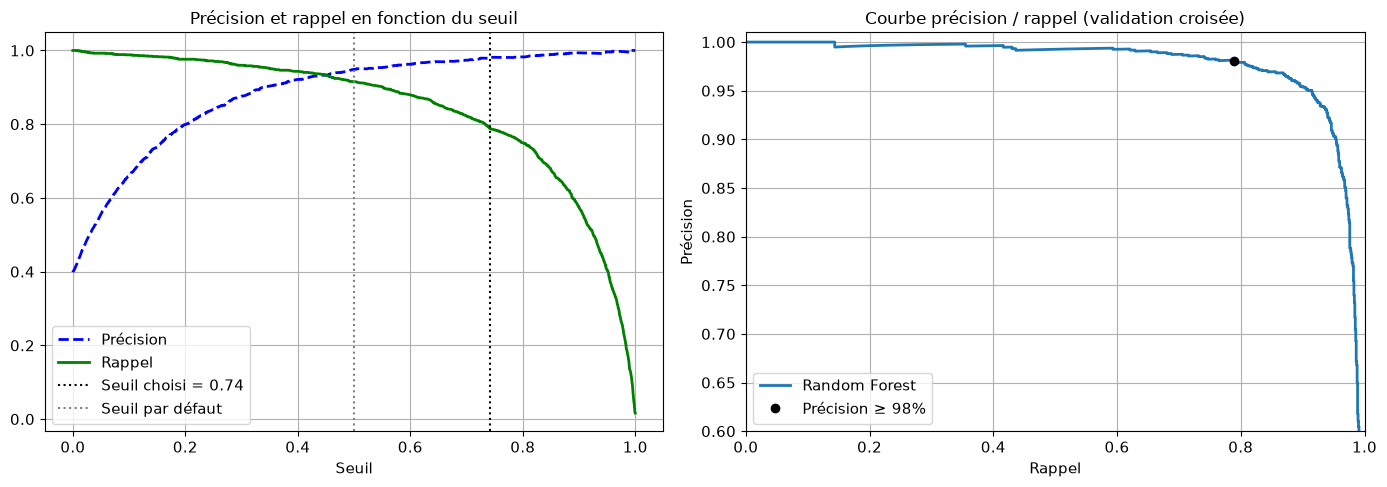

In [26]:
default_threshold = 0.5 if method == "predict_proba" else 0.0

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.plot(thresholds, precisions[:-1], "b--", label="Précision", linewidth=2)
ax.plot(thresholds, recalls[:-1], "g-", label="Rappel", linewidth=2)
ax.axvline(threshold, color="k", linestyle=":", label=f"Seuil choisi = {threshold:.2f}")
ax.axvline(default_threshold, color="gray", linestyle=":", label="Seuil par défaut")
ax.set_xlabel("Seuil")
ax.set_title("Précision et rappel en fonction du seuil")
ax.legend(loc="lower left")
ax.grid(True)

ax = axes[1]
ax.plot(recalls, precisions, linewidth=2, label=best_name)
ax.plot(recalls[idx], precisions[idx], "ko", label=f"Précision ≥ {TARGET_PRECISION:.0%}")
ax.set_xlabel("Rappel")
ax.set_ylabel("Précision")
ax.set_title("Courbe précision / rappel (validation croisée)")
ax.set_xlim(0, 1); ax.set_ylim(0.6, 1.01)
ax.legend(loc="lower left")
ax.grid(True)

save_fig("compromis_precision_rappel")
plt.show()

**Courbes ROC : plus la courbe monte vite, meilleur est le modèle.**

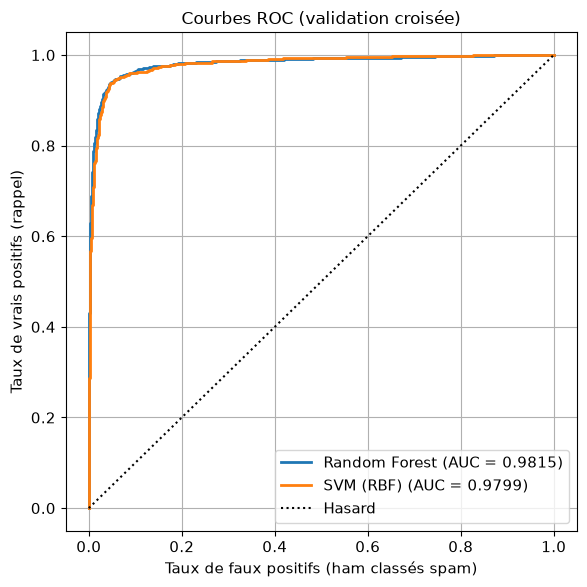

In [27]:
# Courbes ROC des deux modèles affinés (comme au chapitre 3)
fig, ax = plt.subplots(figsize=(6, 6))
for name, search in searches.items():
    model = search.best_estimator_
    m = "predict_proba" if hasattr(model, "predict_proba") else "decision_function"
    s = cross_val_predict(model, X_train, y_train, cv=cv5, method=m)
    s = s[:, 1] if m == "predict_proba" else s
    fpr, tpr, _ = roc_curve(y_train, s)
    ax.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC = {roc_auc_score(y_train, s):.4f})")
ax.plot([0, 1], [0, 1], "k:", label="Hasard")
ax.set_xlabel("Taux de faux positifs (ham classés spam)")
ax.set_ylabel("Taux de vrais positifs (rappel)")
ax.set_title("Courbes ROC (validation croisée)")
ax.legend(loc="lower right")
ax.grid(True)
save_fig("courbes_roc")
plt.show()

## 10. Évaluation sur le jeu de test

**Scores sur le test : seuil par défaut contre seuil choisi.**

In [28]:
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, precision_score, recall_score)


def spam_scores(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)


test_scores = spam_scores(final_model, X_test)
y_pred_default = (test_scores >= default_threshold).astype(int)
y_pred = (test_scores >= threshold).astype(int)

summary = pd.DataFrame({
    "Seuil par défaut": [accuracy_score(y_test, y_pred_default), precision_score(y_test, y_pred_default),
                         recall_score(y_test, y_pred_default), f1_score(y_test, y_pred_default)],
    f"Seuil choisi ({threshold:.2f})": [accuracy_score(y_test, y_pred), precision_score(y_test, y_pred),
                                        recall_score(y_test, y_pred), f1_score(y_test, y_pred)],
}, index=["accuracy", "précision", "rappel", "F1"])
summary.round(4)

,Seuil par défaut,Seuil choisi (0.74)
accuracy,0.9382,0.9192
précision,0.9383,0.9891
rappel,0.9048,0.8065
F1,0.9212,0.8885


**Courbes : matrices de confusion (vrai contre prédit).**

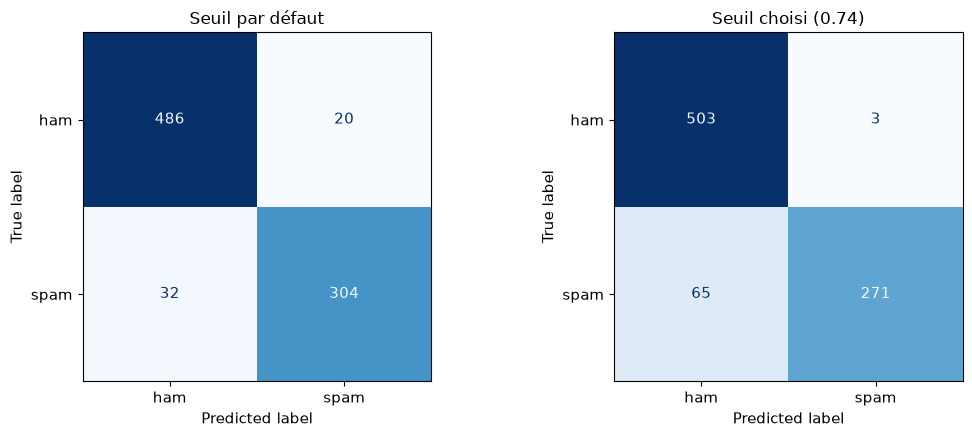

              precision    recall  f1-score   support

         ham     0.8856    0.9941    0.9367       506
        spam     0.9891    0.8065    0.8885       336

    accuracy                         0.9192       842
   macro avg     0.9373    0.9003    0.9126       842
weighted avg     0.9269    0.9192    0.9175       842



In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, pred, title in [(axes[0], y_pred_default, "Seuil par défaut"),
                        (axes[1], y_pred, f"Seuil choisi ({threshold:.2f})")]:
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["ham", "spam"],
                                            cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(title)
save_fig("matrices_confusion_test")
plt.show()

print(classification_report(y_test, y_pred, target_names=["ham", "spam"], digits=4))

**Intervalle de confiance à 95 % (bootstrap).**

In [30]:
rng = np.random.default_rng(42)
y_test_arr, y_pred_arr = y_test.to_numpy(), y_pred
boot = {"précision": [], "rappel": [], "accuracy": []}
for _ in range(1000):
    i = rng.integers(0, len(y_test_arr), len(y_test_arr))
    boot["précision"].append(precision_score(y_test_arr[i], y_pred_arr[i], zero_division=1))
    boot["rappel"].append(recall_score(y_test_arr[i], y_pred_arr[i]))
    boot["accuracy"].append(accuracy_score(y_test_arr[i], y_pred_arr[i]))

for metric, values in boot.items():
    low, high = np.percentile(values, [2.5, 97.5])
    print(f"{metric:10s} : IC 95 % = [{low:.4f} ; {high:.4f}]")

précision  : IC 95 % = [0.9747 ; 1.0000]
rappel     : IC 95 % = [0.7638 ; 0.8435]
accuracy   : IC 95 % = [0.9002 ; 0.9359]


**Les emails où le modèle se trompe.**

In [31]:
# Analyse des erreurs : quels emails le modèle se trompe-t-il ?
errors = X_test.assign(vrai=y_test, predit=y_pred, score=test_scores)
errors = errors[errors["vrai"] != errors["predit"]]
print("Faux positifs (ham -> spam) :", ((errors["vrai"] == 0)).sum())
print("Faux négatifs (spam -> ham) :", ((errors["vrai"] == 1)).sum())
cols = ["vrai", "predit", "score"] + list(importances.head(6).index)
errors[cols].sort_values("score").head(10).round(3)

Faux positifs (ham -> spam) : 3
Faux négatifs (spam -> ham) : 65


,vrai,predit,score,char_freq_!,char_freq_$,word_freq_remove,word_freq_free,capital_run_length_average,word_freq_your
582,1,0,0.063,0.000,0.000,0.0,0.00,1.000,1.63
162,1,0,0.099,0.000,0.000,0.0,0.00,1.100,0.00
612,1,0,0.132,0.000,0.000,0.0,0.00,1.000,0.00
1177,1,0,0.215,0.415,0.000,0.0,0.00,1.909,2.46
1550,1,0,0.229,0.000,0.000,0.0,0.00,3.230,0.00
836,1,0,0.243,0.000,0.000,0.0,0.00,2.000,0.00
1646,1,0,0.279,0.000,0.000,0.0,0.00,1.333,0.85
1428,1,0,0.301,0.000,0.000,0.0,0.00,3.500,0.00
541,1,0,0.304,0.277,0.000,0.0,0.00,3.200,0.00
201,1,0,0.327,0.000,0.022,0.0,0.05,1.423,0.02


- Précision : **98,9 %**
- Rappel : **80,7 %**
- Seulement **3 vrais emails sur 506** classés spam
- Proche de la validation croisée → pas de sur-apprentissage

## 11. Sauvegarde et utilisation

**Sauvegarde du modèle et du seuil.**

In [32]:
import joblib

MODELS_PATH = Path("models")
MODELS_PATH.mkdir(exist_ok=True)

# On réentraîne le pipeline final sur tout le jeu d'entraînement (c'est déjà le cas avec GridSearchCV refit=True)
joblib.dump({"model": final_model, "threshold": threshold, "model_name": best_name,
             "feature_names": list(X_train.columns)},
            MODELS_PATH / "spam_detector.pkl")
print("Modèle sauvegardé dans", MODELS_PATH / "spam_detector.pkl")

Modèle sauvegardé dans models/spam_detector.pkl


**Rechargement du modèle et prédiction sur 8 emails.**

In [33]:
# Utilisation en "production" : on recharge le modèle et on classe quelques emails
bundle = joblib.load(MODELS_PATH / "spam_detector.pkl")


def predict_spam(X_new, bundle=bundle):
    scores = spam_scores(bundle["model"], X_new[bundle["feature_names"]])
    return np.where(scores >= bundle["threshold"], "spam", "ham")


sample = X_test.sample(8, random_state=7)
pd.DataFrame({
    "vraie classe": y_test.loc[sample.index].map({0: "ham", 1: "spam"}),
    "prédiction": predict_spam(sample),
})

,vraie classe,prédiction
1016,spam,ham
1880,ham,ham
3569,ham,ham
3660,ham,ham
1626,spam,spam
3932,ham,ham
131,spam,spam
4015,ham,ham


## Conclusion

- Démarche complète du livre, du problème au modèle sauvegardé
- Meilleur modèle : **Random Forest**
- 98,9 % de précision sur le test
- Limite : données de 1999, une seule entreprise
- Suite : emails bruts + TF-IDF, puis une petite application